# Isothermal 0D Master Equation Simulation
### Import libraries

In [1]:
import os
import sys
import pickle
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm.notebook import tqdm

Visualization libraries

In [2]:
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
# %matplotlib qt
COLORS = mpl.rcParams['axes.prop_cycle'].by_key()['color']

Global paths

In [3]:
# WORKSPACE
WORKSPACE = os.environ['WORKSPACE_PATH']
# SurQCT
SurQCT = WORKSPACE + '/ML/PyCOMET/pycomet/examples/SurQCT/'
sys.path.append(os.path.abspath(SurQCT))
# Current Working Directory
CWD = os.getcwd()

In [4]:
# Output directory
out_dir = CWD + '/../Output/MasterEquation/'
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

### Initializing Run

In [5]:
SystName       = 'O3_UMN'
ProcessesCode  = '0_1_0_0'
TTranVec       = [1500, 5000, 10000, 20000]
RunCase        = '/KInel/case.01/'

Loading chemical system

In [6]:
from surqct.src.ChemicalSystems import Systems
System = getattr(Systems, SystName)()
# Update path to SurQCT folder
System.SurQCTMEPath = System.SurQCTMEPath + RunCase

### Reading Master Equation Solution Files

In [7]:
QCT    = {}
SurQCT = {}

for iTemp in tqdm(range(len(TTranVec))):

    Temp = TTranVec[iTemp]
    
    QCT[Temp] = {}
    SurQCT[Temp] = {}
    
    # QCT
    print(f'\nReading    QCT 0D ME solution at temperature T = {Temp} K')
    PathToRunFldr               = System.QCTMEPath + f'/T{str(Temp)}K/{ProcessesCode}/output_box/'
    QCT[Temp]['box']            = pd.read_csv(PathToRunFldr + 'box.dat', delimiter='  ', skiprows=1, engine='python')
    QCT[Temp]['box'].columns    = System.BoxHeader
    QCT[Temp]['box'].NSteps     = len(QCT[Temp]['box'])
    QCT[Temp]['pop']            = System.read_populations(PathToRunFldr, QCT[Temp]['box'].NSteps)
    
    # SurQCT
    print(f'Reading SurQCT 0D ME solution at temperature T = {Temp} K')
    PathToRunFldr               = System.SurQCTMEPath + f'/T{str(Temp)}K/{ProcessesCode}/output_box/'
    SurQCT[Temp]['box']         = pd.read_csv(PathToRunFldr + 'box.dat', delimiter='  ', skiprows=1, engine='python')
    SurQCT[Temp]['box'].columns = System.BoxHeader
    SurQCT[Temp]['box'].NSteps  = len(SurQCT[Temp]['box'])
    SurQCT[Temp]['pop']         = System.read_populations(PathToRunFldr, QCT[Temp]['box'].NSteps)


  0%|          | 0/4 [00:00<?, ?it/s]


Reading    QCT 0D simulation at Temperature T = 1500 K
Reading SurQCT 0D simulation at Temperature T = 1500 K

Reading    QCT 0D simulation at Temperature T = 5000 K
Reading SurQCT 0D simulation at Temperature T = 5000 K

Reading    QCT 0D simulation at Temperature T = 10000 K
Reading SurQCT 0D simulation at Temperature T = 10000 K

Reading    QCT 0D simulation at Temperature T = 20000 K
Reading SurQCT 0D simulation at Temperature T = 20000 K


### Computing
Energies

In [8]:
for iTemp in tqdm(range(len(TTranVec))):
    
    Temp = TTranVec[iTemp]
    
    QCT[Temp]['E'] = System.compute_energies(Ni=QCT[Temp]['pop'])
    SurQCT[Temp]['E'] = System.compute_energies(Ni=SurQCT[Temp]['pop'])


  0%|          | 0/4 [00:00<?, ?it/s]

### Plotting
Energies

In [25]:
def plot_energies(
    Path,
    System,
    QCT,
    SurQCT,
    TTranVec,
    xlim=[1.e-10, 1.e-4],
    figsize_factor=1.
):
    iTemp = 0
    fig = plt.figure(figsize=np.array([6.4,4.8])*figsize_factor)
    plt.plot([], [],'--k', label='$E_{Rot}$')
    plt.plot([], [], '-k', label='$E_{Vib}$')
    plt.plot([], [], label='QCT', c=COLORS[0])
    plt.plot([], [], label='SurQCT', c=COLORS[1])

    for iTemp in range(len(TTranVec)):

        Temp = TTranVec[iTemp]
        
        for iMol, Mol in enumerate(System.Molecule):
            # QCT
            t = QCT[Temp]['box'].time
            plt.plot(t, QCT[Temp]['E']['ERot'][Mol.Name], '--', c=COLORS[0])
            plt.plot(t, QCT[Temp]['E']['EVib'][Mol.Name],  '-', c=COLORS[0])

            # SurQCT
            t = SurQCT[Temp]['box'].time
            plt.plot(t, SurQCT[Temp]['E']['ERot'][Mol.Name], '--', c=COLORS[1])
            plt.plot(t, SurQCT[Temp]['E']['EVib'][Mol.Name],  '-', c=COLORS[1])
            
            # Temperature annotation
            xy = (1, max(
                QCT[Temp]['E']['ERot'][Mol.Name][-1],
                SurQCT[Temp]['E']['ERot'][Mol.Name][-1]
            ))
            plt.annotate(
                'T = %d K' % Temp,
                xy=xy,
                xytext=(8, 0),
                xycoords=('axes fraction', 'data'),
                textcoords='offset points'
            )

        plt.legend()
        plt.xscale('log')
        plt.xlabel('$t$ [s]')
        plt.ylabel('$E$ [eV]')
        plt.xlim(xlim)

    plt.savefig(Path + f'/EVib_ERot_{ProcessesCode}.pdf', bbox_inches="tight")


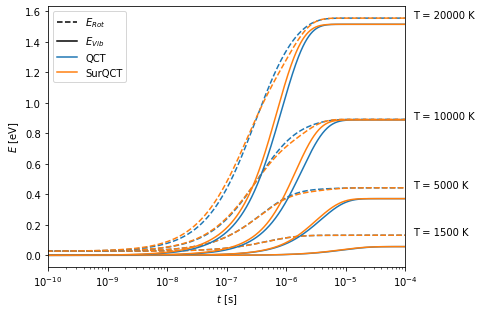

In [26]:
plot_energies(out_dir, System, QCT, SurQCT, TTranVec)

Populations